# IFN680 Project 7 — DDPM Schedule Comparison

## Task 2: Inference and Evaluation

This notebook loads the two pre-trained conditional DDPM models produced by
`DDPM_CosineSchedule.ipynb` and compares the Linear and Cosine noise schedules.

The notebook reproduces the evidence required for the report:

- loads both trained model checkpoints without retraining;
- generates 12 samples for every digit class 0–9;
- produces 120 generated images for each model;
- visually compares conditional generation quality, consistency and variety;
- compares training loss and training runtime; and
- compares full DDPM inference runtime.

The same requested labels and random seed are used for both models to make the
Linear and Cosine comparison controlled and reproducible.

## 1. Setup and Reproducibility

In [1]:
from pathlib import Path
import random
import time
import csv

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from tqdm.auto import tqdm


# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.13.0+cu126
Device: cuda
GPU: NVIDIA A16-4Q


## 2. File Paths

The two trained checkpoints are expected in the `checkpoints` directory created
by the training notebook.

No model training is performed in this notebook.

In [2]:
CHECKPOINT_DIR = Path("checkpoints")

LINEAR_CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "ddpm_linear.pt"
)

COSINE_CHECKPOINT_PATH = (
    CHECKPOINT_DIR / "ddpm_cosine.pt"
)

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


required_files = [
    LINEAR_CHECKPOINT_PATH,
    COSINE_CHECKPOINT_PATH,
]


for file_path in required_files:
    if not file_path.exists():
        raise FileNotFoundError(
            f"Required file not found: "
            f"{file_path.resolve()}"
        )


print("Files found:")
print(
    f"  Linear checkpoint: "
    f"{LINEAR_CHECKPOINT_PATH}"
)
print(
    f"  Cosine checkpoint: "
    f"{COSINE_CHECKPOINT_PATH}"
)
print(
    f"  Results directory: "
    f"{RESULTS_DIR}"
)

Files found:
  Linear checkpoint: checkpoints/ddpm_linear.pt
  Cosine checkpoint: checkpoints/ddpm_cosine.pt
  Results directory: results


## 3. Load Checkpoints

The checkpoint metadata is inspected before the models are reconstructed. This
helps ensure that inference uses the same architecture and configuration that
were used during training.

In [3]:
linear_checkpoint = torch.load(
    LINEAR_CHECKPOINT_PATH,
    map_location=device
)

cosine_checkpoint = torch.load(
    COSINE_CHECKPOINT_PATH,
    map_location=device
)


required_checkpoint_keys = {
    "model_state_dict",
    "schedule",
    "timesteps",
    "unet_channels",
    "num_classes",
    "epochs",
    "learning_rate",
    "training_history",
}


assert required_checkpoint_keys.issubset(
    linear_checkpoint.keys()
)

assert required_checkpoint_keys.issubset(
    cosine_checkpoint.keys()
)


assert linear_checkpoint["schedule"] == "linear"
assert cosine_checkpoint["schedule"] == "cosine"


LINEAR_TIMESTEPS = int(
    linear_checkpoint["timesteps"]
)

COSINE_TIMESTEPS = int(
    cosine_checkpoint["timesteps"]
)

UNET_CHANNELS = int(
    linear_checkpoint["unet_channels"]
)

NUM_CLASSES = int(
    linear_checkpoint["num_classes"]
)

CHANNELS = 1
IMAGE_SIZE = 20


assert (
    linear_checkpoint["unet_channels"]
    == cosine_checkpoint["unet_channels"]
)

assert (
    linear_checkpoint["num_classes"]
    == cosine_checkpoint["num_classes"]
)


print("Checkpoint Configuration")
print("-" * 55)

print(
    f"{'':20}"
    f"{'Linear':>15}"
    f"{'Cosine':>15}"
)

print(
    f"{'Schedule':20}"
    f"{linear_checkpoint['schedule']:>15}"
    f"{cosine_checkpoint['schedule']:>15}"
)

print(
    f"{'Timesteps':20}"
    f"{LINEAR_TIMESTEPS:>15}"
    f"{COSINE_TIMESTEPS:>15}"
)

print(
    f"{'Epochs':20}"
    f"{linear_checkpoint['epochs']:>15}"
    f"{cosine_checkpoint['epochs']:>15}"
)

print(
    f"{'Learning rate':20}"
    f"{linear_checkpoint['learning_rate']:>15.2e}"
    f"{cosine_checkpoint['learning_rate']:>15.2e}"
)

print(
    f"{'U-Net channels':20}"
    f"{UNET_CHANNELS:>15}"
    f"{UNET_CHANNELS:>15}"
)

print(
    f"{'Classes':20}"
    f"{NUM_CLASSES:>15}"
    f"{NUM_CLASSES:>15}"
)

Checkpoint Configuration
-------------------------------------------------------
                             Linear         Cosine
Schedule                     linear         cosine
Timesteps                      1000           1000
Epochs                          150            150
Learning rate              2.00e-04       2.00e-04
U-Net channels                   32             32
Classes                          10             10


## 4. Conditional U-Net Architecture

The same conditional U-Net architecture used during training is reconstructed
before loading the saved model parameters.

The network receives:

- noisy image \(x_t\);
- diffusion timestep \(t\); and
- requested digit class \(y\).

It predicts the Gaussian noise present in the noisy image.

In [4]:
class ConvBlock(nn.Module):
    def __init__(
        self,
        in_ch,
        out_ch
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(
                in_ch,
                out_ch,
                3,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                out_ch,
                out_ch,
                3,
                padding=1
            ),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class UNet_cond(nn.Module):
    def __init__(
        self,
        ch=32,
        n_classes=10,
        num_timesteps=1000
    ):
        super().__init__()

        self.num_timesteps = num_timesteps

        # Encoder
        self.enc1 = ConvBlock(
            CHANNELS,
            ch
        )

        self.enc2 = ConvBlock(
            ch,
            ch * 2
        )

        # Bottleneck
        self.bot = ConvBlock(
            ch * 2,
            ch * 2
        )

        # Decoder
        self.dec2 = ConvBlock(
            ch * 2 + ch * 2,
            ch
        )

        self.dec1 = ConvBlock(
            ch + ch,
            ch
        )

        # Final predicted-noise image
        self.final = nn.Conv2d(
            ch,
            CHANNELS,
            1
        )

        # Timestep embedding
        self.time_mlp = nn.Sequential(
            nn.Linear(1, ch),
            nn.ReLU(),
            nn.Linear(ch, ch)
        )

        # Class embedding
        self.class_emb = nn.Embedding(
            n_classes,
            ch
        )

        # Conditioning projections
        self.to_e1 = nn.Conv2d(
            ch,
            ch,
            1
        )

        self.to_e2 = nn.Conv2d(
            ch,
            ch * 2,
            1
        )

        self.to_b = nn.Conv2d(
            ch,
            ch * 2,
            1
        )

        self.to_d2 = nn.Conv2d(
            ch,
            ch,
            1
        )

        self.to_d1 = nn.Conv2d(
            ch,
            ch,
            1
        )

        self.pool = nn.AvgPool2d(2)

        self.upsample = nn.Upsample(
            scale_factor=2,
            mode="nearest"
        )

    def forward(
        self,
        x,
        t,
        y
    ):
        # Normalised timestep embedding
        t = (
            t.float().unsqueeze(-1)
            / self.num_timesteps
        )

        t_emb = (
            self.time_mlp(t)
            .unsqueeze(-1)
            .unsqueeze(-1)
        )

        # Class embedding
        y_emb = (
            self.class_emb(y)
            .unsqueeze(-1)
            .unsqueeze(-1)
        )

        # Combined conditioning
        cond_emb = t_emb + y_emb

        # Encoder
        e1 = (
            self.enc1(x)
            + self.to_e1(cond_emb)
        )

        e2 = (
            self.enc2(
                self.pool(e1)
            )
            + self.to_e2(cond_emb)
        )

        # Bottleneck
        b = (
            self.bot(
                self.pool(e2)
            )
            + self.to_b(cond_emb)
        )

        # Decoder
        d2 = self.upsample(b)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = (
            self.dec2(d2)
            + self.to_d2(cond_emb)
        )

        d1 = self.upsample(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = (
            self.dec1(d1)
            + self.to_d1(cond_emb)
        )

        return self.final(d1)

## 5. Noise Schedules

The Linear schedule is reproduced from the Week 9 tutorial implementation.

The Cosine schedule defines cumulative signal retention using a cosine curve and
derives the beta values from consecutive cumulative alpha values.

In [5]:
def linear_beta_schedule(
    timesteps,
    beta_start=1e-4,
    beta_end=0.02
):
    return torch.linspace(
        beta_start,
        beta_end,
        timesteps
    )


def cosine_beta_schedule(
    timesteps,
    s=0.008
):
    steps = timesteps + 1

    x = torch.linspace(
        0,
        timesteps,
        steps
    )

    alpha_bars = torch.cos(
        (
            (x / timesteps + s)
            / (1 + s)
        )
        * torch.pi
        / 2
    ) ** 2

    # Normalise so alpha_bar begins at 1.
    alpha_bars = (
        alpha_bars
        / alpha_bars[0]
    )

    betas = (
        1.0
        - (
            alpha_bars[1:]
            / alpha_bars[:-1]
        )
    )

    return torch.clamp(
        betas,
        min=1e-4,
        max=0.999
    )


def prepare_diffusion_coefficients(
    betas
):
    alphas = 1.0 - betas

    alpha_bars = torch.cumprod(
        alphas,
        dim=0
    )

    return {
        "betas":
            betas,

        "alphas":
            alphas,

        "alpha_bars":
            alpha_bars,

        "sqrt_alpha_bars":
            torch.sqrt(
                alpha_bars
            ),

        "sqrt_one_minus_alpha_bars":
            torch.sqrt(
                1.0 - alpha_bars
            ),

        "sqrt_recip_alphas":
            torch.sqrt(
                1.0 / alphas
            ),
    }

In [6]:
linear_betas = linear_beta_schedule(
    LINEAR_TIMESTEPS
).to(device)

cosine_betas = cosine_beta_schedule(
    COSINE_TIMESTEPS
).to(device)


linear_schedule = (
    prepare_diffusion_coefficients(
        linear_betas
    )
)

cosine_schedule = (
    prepare_diffusion_coefficients(
        cosine_betas
    )
)


print("Linear schedule")
print(
    f"  Beta range: "
    f"{linear_betas.min().item():.6f} "
    f"to "
    f"{linear_betas.max().item():.6f}"
)

print(
    f"  Final alpha_bar: "
    f"{linear_schedule['alpha_bars'][-1].item():.8f}"
)


print("\nCosine schedule")

print(
    f"  Beta range: "
    f"{cosine_betas.min().item():.6f} "
    f"to "
    f"{cosine_betas.max().item():.6f}"
)

print(
    f"  Final alpha_bar: "
    f"{cosine_schedule['alpha_bars'][-1].item():.8f}"
)

Linear schedule
  Beta range: 0.000100 to 0.020000
  Final alpha_bar: 0.00004036

Cosine schedule
  Beta range: 0.000100 to 0.999000
  Final alpha_bar: 0.00000000


## 6. Load the Trained Models

In [7]:
linear_model = UNet_cond(
    ch=UNET_CHANNELS,
    n_classes=NUM_CLASSES,
    num_timesteps=LINEAR_TIMESTEPS
).to(device)


cosine_model = UNet_cond(
    ch=UNET_CHANNELS,
    n_classes=NUM_CLASSES,
    num_timesteps=COSINE_TIMESTEPS
).to(device)


linear_model.load_state_dict(
    linear_checkpoint[
        "model_state_dict"
    ]
)


cosine_model.load_state_dict(
    cosine_checkpoint[
        "model_state_dict"
    ]
)


linear_model.eval()
cosine_model.eval()


linear_parameter_count = sum(
    parameter.numel()
    for parameter
    in linear_model.parameters()
)

cosine_parameter_count = sum(
    parameter.numel()
    for parameter
    in cosine_model.parameters()
)


print("Models loaded successfully.")

print(
    f"Linear parameters: "
    f"{linear_parameter_count:,}"
)

print(
    f"Cosine parameters: "
    f"{cosine_parameter_count:,}"
)

assert (
    linear_parameter_count
    == cosine_parameter_count
)

Models loaded successfully.
Linear parameters: 221,569
Cosine parameters: 221,569


## 7. Visualise the Noise Schedules

The cumulative alpha curve represents the proportion of the original signal
retained through the forward diffusion process.

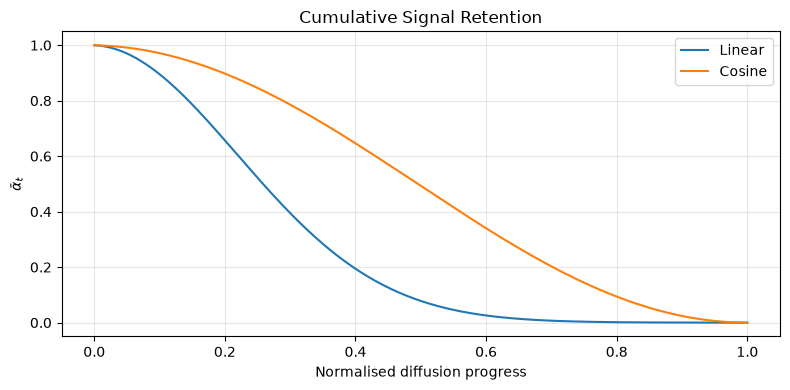

In [8]:
plt.figure(
    figsize=(8, 4)
)


linear_progress = np.linspace(
    0,
    1,
    LINEAR_TIMESTEPS
)

cosine_progress = np.linspace(
    0,
    1,
    COSINE_TIMESTEPS
)


plt.plot(
    linear_progress,
    linear_schedule[
        "alpha_bars"
    ].detach().cpu(),
    label="Linear"
)

plt.plot(
    cosine_progress,
    cosine_schedule[
        "alpha_bars"
    ].detach().cpu(),
    label="Cosine"
)


plt.xlabel(
    "Normalised diffusion progress"
)

plt.ylabel(
    r"$\bar{\alpha}_t$"
)

plt.title(
    "Cumulative Signal Retention"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / "schedule_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 8. Full DDPM Reverse Process

The original ancestral DDPM reverse process is retained for the primary
assessment output.

This sampler moves through every adjacent timestep from \(T-1\) to 0 and uses
the coefficients corresponding to the model's own noise schedule.

In [9]:
def extract(
    values,
    timesteps_batch,
    x_shape
):
    batch_size = (
        timesteps_batch.shape[0]
    )

    out = values.gather(
        0,
        timesteps_batch
    )

    return out.reshape(
        batch_size,
        *((1,) * (
            len(x_shape) - 1
        ))
    )

In [10]:
@torch.no_grad()
def p_sample_cddpm(
    model,
    x_t,
    t_index,
    labels,
    schedule
):
    t = torch.full(
        (x_t.shape[0],),
        t_index,
        device=x_t.device,
        dtype=torch.long
    )

    beta = extract(
        schedule["betas"],
        t,
        x_t.shape
    )

    alpha = extract(
        schedule["alphas"],
        t,
        x_t.shape
    )

    alpha_bar = extract(
        schedule["alpha_bars"],
        t,
        x_t.shape
    )

    sigma = torch.sqrt(
        beta
    )

    predicted_noise = model(
        x_t,
        t,
        labels
    )

    if t_index == 0:
        z = 0
    else:
        z = torch.randn_like(
            x_t
        )

    x_previous = (
        1.0
        / torch.sqrt(alpha)
        * (
            x_t
            - beta
            / torch.sqrt(
                1.0 - alpha_bar
            )
            * predicted_noise
        )
        + sigma * z
    )

    return x_previous

In [11]:
@torch.no_grad()
def sample_cddpm(
    model,
    labels,
    schedule,
    num_timesteps,
    seed=1337,
    image_size=20,
    show_progress=True
):
    model.eval()

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )

    n_samples = labels.shape[0]

    x = torch.randn(
        n_samples,
        CHANNELS,
        image_size,
        image_size,
        device=device
    )

    iterator = reversed(
        range(num_timesteps)
    )

    if show_progress:
        iterator = tqdm(
            iterator,
            total=num_timesteps,
            desc=(
                f"DDPM sampling "
                f"({num_timesteps} steps)"
            )
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = (
        time.perf_counter()
    )

    for t_index in iterator:
        x = p_sample_cddpm(
            model=model,
            x_t=x,
            t_index=t_index,
            labels=labels,
            schedule=schedule
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_seconds = (
        time.perf_counter()
        - start_time
    )

    return (
        x.clamp(-1, 1),
        elapsed_seconds
    )

## 9. Required Conditional Labels

The assessment requires exactly 12 generated examples for each class 0–9.

This gives:

\[
12 \times 10 = 120
\]

generated images for each model.

In [12]:
SAMPLES_PER_CLASS = 12
SAMPLING_SEED = 1337


labels = torch.arange(
    NUM_CLASSES,
    device=device,
    dtype=torch.long
).repeat_interleave(
    SAMPLES_PER_CLASS
)


assert labels.shape[0] == 120


print(
    f"Classes: "
    f"{NUM_CLASSES}"
)

print(
    f"Samples per class: "
    f"{SAMPLES_PER_CLASS}"
)

print(
    f"Total samples per model: "
    f"{labels.shape[0]}"
)

Classes: 10
Samples per class: 12
Total samples per model: 120


## 10. Generate 120 Samples — Linear Schedule

In [13]:
linear_samples, linear_ddpm_time = (
    sample_cddpm(
        model=linear_model,
        labels=labels,
        schedule=linear_schedule,
        num_timesteps=LINEAR_TIMESTEPS,
        seed=SAMPLING_SEED,
        image_size=IMAGE_SIZE
    )
)


assert linear_samples.shape == (
    120,
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert torch.isfinite(
    linear_samples
).all()


print(
    f"Linear sample shape: "
    f"{linear_samples.shape}"
)

print(
    f"Linear DDPM runtime: "
    f"{linear_ddpm_time:.2f} seconds"
)

DDPM sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

Linear sample shape: torch.Size([120, 1, 20, 20])
Linear DDPM runtime: 4.74 seconds


## 11. Generate 120 Samples — Cosine Schedule

In [14]:
cosine_samples, cosine_ddpm_time = (
    sample_cddpm(
        model=cosine_model,
        labels=labels,
        schedule=cosine_schedule,
        num_timesteps=COSINE_TIMESTEPS,
        seed=SAMPLING_SEED,
        image_size=IMAGE_SIZE
    )
)


assert cosine_samples.shape == (
    120,
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert torch.isfinite(
    cosine_samples
).all()


print(
    f"Cosine sample shape: "
    f"{cosine_samples.shape}"
)

print(
    f"Cosine DDPM runtime: "
    f"{cosine_ddpm_time:.2f} seconds"
)

DDPM sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

Cosine sample shape: torch.Size([120, 1, 20, 20])
Cosine DDPM runtime: 4.56 seconds


## 12. Required 12 × 10 Generation Grids

Each row corresponds to one requested digit class.

The 12 columns allow visual assessment of:

- class consistency;
- recognisability;
- image quality; and
- within-class diversity.

In [15]:
def plot_class_grid(
    samples,
    schedule_name,
    num_timesteps,
    save_name
):
    display_samples = (
        (samples.detach().cpu() + 1.0)
        / 2.0
    ).clamp(
        0,
        1
    )

    fig, axes = plt.subplots(
        NUM_CLASSES,
        SAMPLES_PER_CLASS,
        figsize=(15, 12)
    )

    for digit in range(
        NUM_CLASSES
    ):
        start_index = (
            digit
            * SAMPLES_PER_CLASS
        )

        for sample_number in range(
            SAMPLES_PER_CLASS
        ):
            ax = axes[
                digit,
                sample_number
            ]

            image = display_samples[
                start_index
                + sample_number,
                0
            ]

            ax.imshow(
                image,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            ax.axis("off")

            if sample_number == 0:
                ax.set_ylabel(
                    str(digit),
                    rotation=0,
                    labelpad=12,
                    fontsize=11,
                    va="center"
                )

    fig.suptitle(
        f"{schedule_name} Schedule — "
        f"12 Samples per Digit "
        f"(T={num_timesteps})",
        fontsize=14
    )

    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.98
        ]
    )

    output_path = (
        RESULTS_DIR
        / save_name
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"Saved: "
        f"{output_path}"
    )

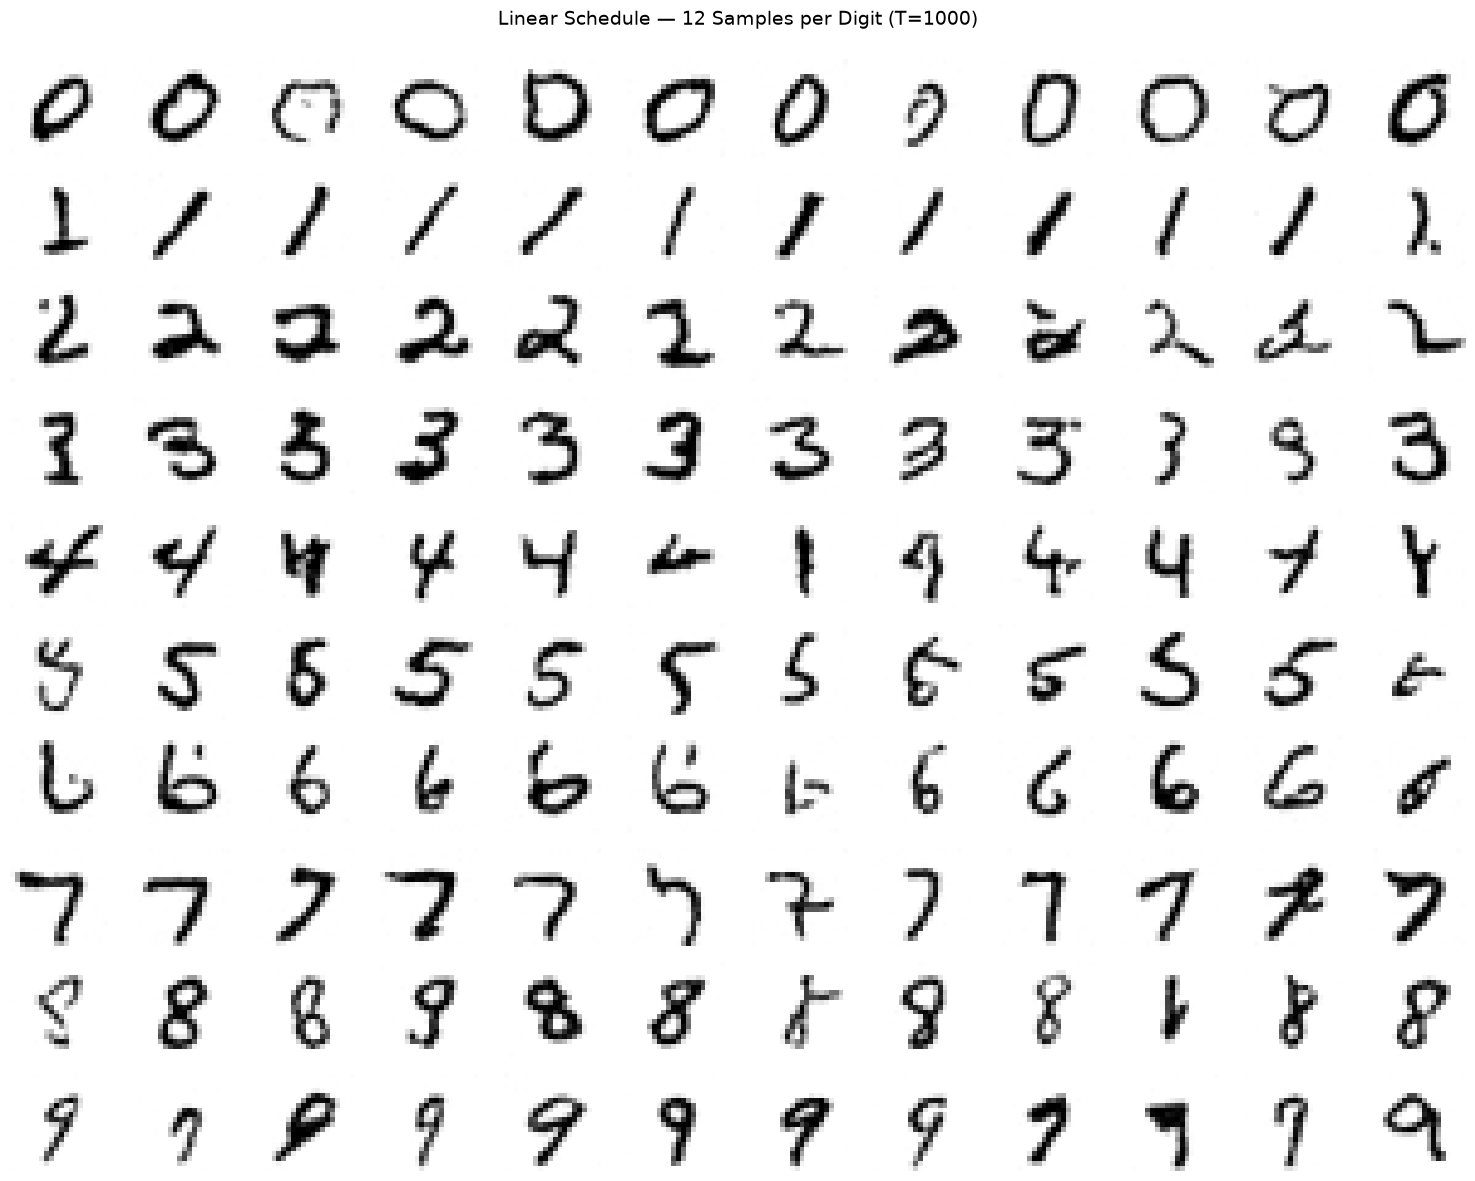

Saved: results/linear_120_samples.png


In [16]:
plot_class_grid(
    samples=linear_samples,
    schedule_name="Linear",
    num_timesteps=LINEAR_TIMESTEPS,
    save_name="linear_120_samples.png"
)

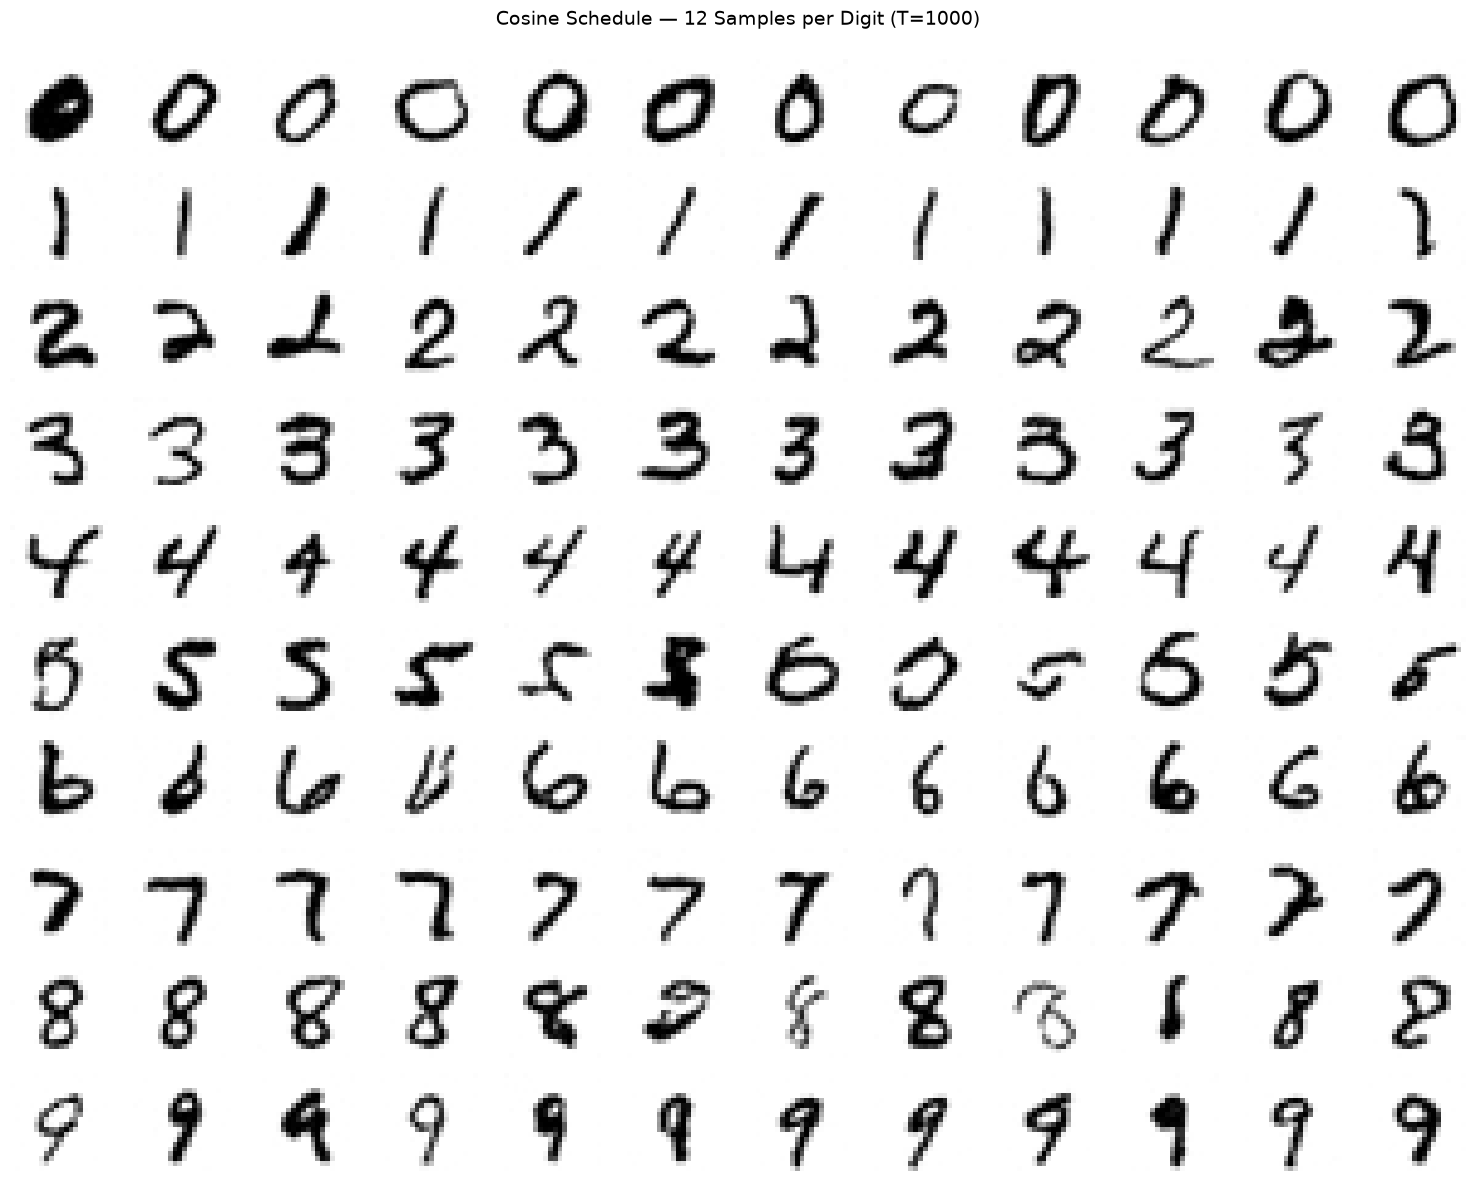

Saved: results/cosine_120_samples.png


In [17]:
plot_class_grid(
    samples=cosine_samples,
    schedule_name="Cosine",
    num_timesteps=COSINE_TIMESTEPS,
    save_name="cosine_120_samples.png"
)

## 13. Compact Linear vs Cosine Comparison

The complete 120-image grids provide the main evidence for consistency and
diversity.

The following compact figure shows one corresponding generated sample from each
digit class for easier direct comparison in the report.

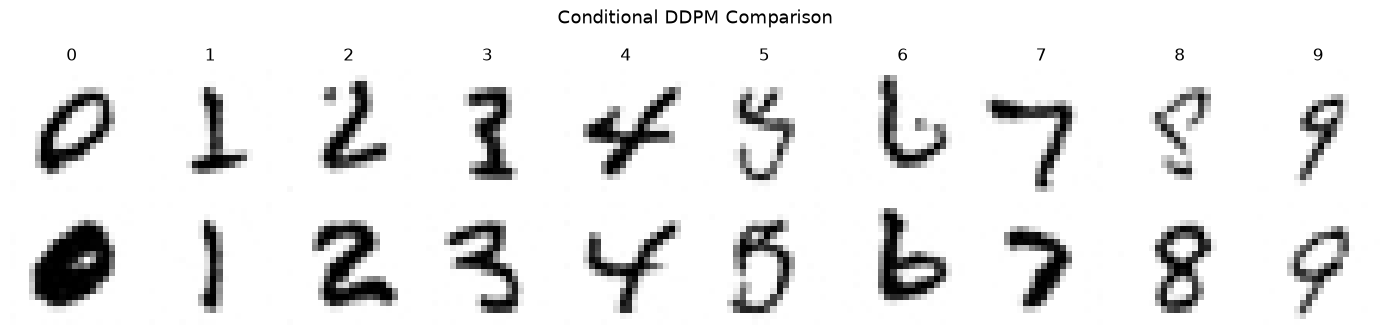

In [18]:
linear_display = (
    (linear_samples.detach().cpu() + 1.0)
    / 2.0
).clamp(
    0,
    1
)

cosine_display = (
    (cosine_samples.detach().cpu() + 1.0)
    / 2.0
).clamp(
    0,
    1
)


fig, axes = plt.subplots(
    2,
    NUM_CLASSES,
    figsize=(14, 3.5)
)


for digit in range(
    NUM_CLASSES
):
    sample_index = (
        digit
        * SAMPLES_PER_CLASS
    )

    axes[
        0,
        digit
    ].imshow(
        linear_display[
            sample_index,
            0
        ],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[
        0,
        digit
    ].set_title(
        str(digit)
    )

    axes[
        0,
        digit
    ].axis("off")


    axes[
        1,
        digit
    ].imshow(
        cosine_display[
            sample_index,
            0
        ],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[
        1,
        digit
    ].axis("off")


axes[0, 0].set_ylabel(
    "Linear",
    fontsize=11
)

axes[1, 0].set_ylabel(
    "Cosine",
    fontsize=11
)


plt.suptitle(
    "Conditional DDPM Comparison",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / "linear_vs_cosine_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 14. Training Results from the Saved Checkpoints

The training histories are stored inside the checkpoints, so the training
comparison can be reproduced without training either model again.

Training MSE measures noise-prediction error. Because the Linear and Cosine
schedules expose the models to different noise distributions across timesteps,
raw training MSE should not be interpreted as a standalone measure of generated
image quality.

In [19]:
linear_history = (
    linear_checkpoint[
        "training_history"
    ]
)

cosine_history = (
    cosine_checkpoint[
        "training_history"
    ]
)


linear_training_time = float(
    linear_history[
        "training_time_seconds"
    ]
)

cosine_training_time = float(
    cosine_history[
        "training_time_seconds"
    ]
)


linear_final_loss = float(
    linear_history[
        "loss"
    ][-1]
)

cosine_final_loss = float(
    cosine_history[
        "loss"
    ][-1]
)


print("Training Comparison")
print("-" * 55)

print(
    f"{'Metric':25}"
    f"{'Linear':>15}"
    f"{'Cosine':>15}"
)

print("-" * 55)

print(
    f"{'Epochs':25}"
    f"{len(linear_history['loss']):>15}"
    f"{len(cosine_history['loss']):>15}"
)

print(
    f"{'Final MSE':25}"
    f"{linear_final_loss:>15.6f}"
    f"{cosine_final_loss:>15.6f}"
)

print(
    f"{'Training time (s)':25}"
    f"{linear_training_time:>15.2f}"
    f"{cosine_training_time:>15.2f}"
)

print(
    f"{'DDPM inference (s)':25}"
    f"{linear_ddpm_time:>15.2f}"
    f"{cosine_ddpm_time:>15.2f}"
)

Training Comparison
-------------------------------------------------------
Metric                            Linear         Cosine
-------------------------------------------------------
Epochs                               150            150
Final MSE                       0.028199       0.047993
Training time (s)                1211.42        1210.30
DDPM inference (s)                  4.74           4.56


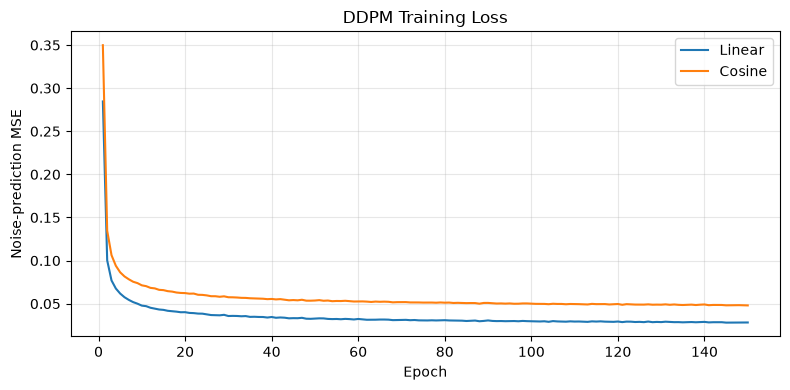

In [20]:
plt.figure(
    figsize=(8, 4)
)


plt.plot(
    range(
        1,
        len(
            linear_history[
                "loss"
            ]
        ) + 1
    ),
    linear_history[
        "loss"
    ],
    label="Linear"
)


plt.plot(
    range(
        1,
        len(
            cosine_history[
                "loss"
            ]
        ) + 1
    ),
    cosine_history[
        "loss"
    ],
    label="Cosine"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Noise-prediction MSE"
)

plt.title(
    "DDPM Training Loss"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()


plt.savefig(
    RESULTS_DIR
    / "training_loss_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 15. Reduced-Step Inference Experiment

The project hypothesis states that a cosine schedule may retain good generation
quality using fewer timesteps than a linear schedule.

The standard DDPM sampler above uses all 1000 reverse steps. To investigate the
fewer-timestep part of the hypothesis without retraining the models, a reduced-step
deterministic DDIM-style sampler is used as an inference-time extension.

This extension keeps:

- the same trained Linear and Cosine models;
- the same conditional U-Net architecture;
- the same requested digit labels;
- the same initial random seed; and
- the same output plotting procedure.

Only the number of reverse-process model evaluations is reduced.

In [21]:
@torch.no_grad()
def sample_ddim_reduced(
    model,
    labels,
    schedule,
    total_training_timesteps,
    sampling_steps,
    seed=1337,
    image_size=20,
    show_progress=True
):
    """
    Deterministic DDIM-style reduced-step sampling.

    The model was trained with total_training_timesteps (e.g. 1000),
    but inference only evaluates a reduced number of timesteps.
    """

    if sampling_steps < 2:
        raise ValueError("sampling_steps must be at least 2.")

    if sampling_steps > total_training_timesteps:
        raise ValueError(
            "sampling_steps cannot exceed total_training_timesteps."
        )

    model.eval()

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    n_samples = labels.shape[0]

    x = torch.randn(
        n_samples,
        CHANNELS,
        image_size,
        image_size,
        device=device
    )

    # Evenly spaced timestep indices, then reversed for denoising.
    timestep_sequence = np.linspace(
        0,
        total_training_timesteps - 1,
        sampling_steps,
        dtype=np.int64
    )[::-1].copy()

    iterator = range(len(timestep_sequence))

    if show_progress:
        iterator = tqdm(
            iterator,
            total=len(timestep_sequence),
            desc=f"Reduced-step sampling ({sampling_steps} steps)"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for i in iterator:
        t_index = int(timestep_sequence[i])

        if i == len(timestep_sequence) - 1:
            prev_t_index = -1
        else:
            prev_t_index = int(timestep_sequence[i + 1])

        t = torch.full(
            (n_samples,),
            t_index,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(
            x,
            t,
            labels
        )

        alpha_bar_t = schedule["alpha_bars"][t_index].reshape(1, 1, 1, 1)

        if prev_t_index < 0:
            alpha_bar_prev = torch.ones(
                (1, 1, 1, 1),
                device=device
            )
        else:
            alpha_bar_prev = schedule["alpha_bars"][prev_t_index].reshape(
                1, 1, 1, 1
            )

        predicted_x0 = (
            x
            - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        predicted_x0 = predicted_x0.clamp(-1, 1)

        # Deterministic DDIM update (eta = 0)
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev) * predicted_noise
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_seconds = time.perf_counter() - start_time

    return x.clamp(-1, 1), elapsed_seconds

### 15.1 Run Reduced-Step Inference

The same 120 requested labels are used for both models, but the number of
reverse-process evaluations is reduced.

The tested step counts are:

- 500
- 250
- 100
- 50

In [22]:
REDUCED_STEP_COUNTS = [500, 250, 100, 50]

reduced_results = {
    "linear": {},
    "cosine": {},
}

for sampling_steps in REDUCED_STEP_COUNTS:
    print("\n" + "=" * 65)
    print(f"Running reduced-step inference: {sampling_steps} steps")
    print("=" * 65)

    linear_reduced_samples, linear_reduced_time = sample_ddim_reduced(
        model=linear_model,
        labels=labels,
        schedule=linear_schedule,
        total_training_timesteps=LINEAR_TIMESTEPS,
        sampling_steps=sampling_steps,
        seed=SAMPLING_SEED,
        image_size=IMAGE_SIZE
    )

    reduced_results["linear"][sampling_steps] = {
        "samples": linear_reduced_samples,
        "runtime": linear_reduced_time,
    }

    cosine_reduced_samples, cosine_reduced_time = sample_ddim_reduced(
        model=cosine_model,
        labels=labels,
        schedule=cosine_schedule,
        total_training_timesteps=COSINE_TIMESTEPS,
        sampling_steps=sampling_steps,
        seed=SAMPLING_SEED,
        image_size=IMAGE_SIZE
    )

    reduced_results["cosine"][sampling_steps] = {
        "samples": cosine_reduced_samples,
        "runtime": cosine_reduced_time,
    }

    print(
        f"Linear runtime: {linear_reduced_time:.2f} s | "
        f"Cosine runtime: {cosine_reduced_time:.2f} s"
    )


Running reduced-step inference: 500 steps


Reduced-step sampling (500 steps):   0%|          | 0/500 [00:00<?, ?it/s]

Reduced-step sampling (500 steps):   0%|          | 0/500 [00:00<?, ?it/s]

Linear runtime: 2.24 s | Cosine runtime: 2.24 s

Running reduced-step inference: 250 steps


Reduced-step sampling (250 steps):   0%|          | 0/250 [00:00<?, ?it/s]

...

Reduced-step sampling (100 steps):   0%|          | 0/100 [00:00<?, ?it/s]

Linear runtime: 0.45 s | Cosine runtime: 0.45 s

Running reduced-step inference: 50 steps


Reduced-step sampling (50 steps):   0%|          | 0/50 [00:00<?, ?it/s]

Reduced-step sampling (50 steps):   0%|          | 0/50 [00:00<?, ?it/s]

Linear runtime: 0.23 s | Cosine runtime: 0.23 s


### 15.2 Reduced-Step Runtime Summary

In [23]:
print("Reduced-Step Inference Runtime Summary")
print("-" * 70)

print(
    f"{'Steps':12}"
    f"{'Linear (s)':>18}"
    f"{'Cosine (s)':>18}"
)

print("-" * 70)

for sampling_steps in REDUCED_STEP_COUNTS:
    linear_time = reduced_results["linear"][sampling_steps]["runtime"]
    cosine_time = reduced_results["cosine"][sampling_steps]["runtime"]

    print(
        f"{sampling_steps:<12}"
        f"{linear_time:>18.2f}"
        f"{cosine_time:>18.2f}"
    )

Reduced-Step Inference Runtime Summary
----------------------------------------------------------------------
Steps               Linear (s)        Cosine (s)
----------------------------------------------------------------------
500                       2.24              2.24
250                       1.13              1.12
100                       0.45              0.45
50                        0.23              0.23


### 15.3 Compact Reduced-Step Visual Comparison

For readability, the figure below shows one generated sample per class for each
reduced-step setting.

This is intended for comparison in the report. The required full 120-image grids
remain the primary evidence for the full 1000-step inference setting.

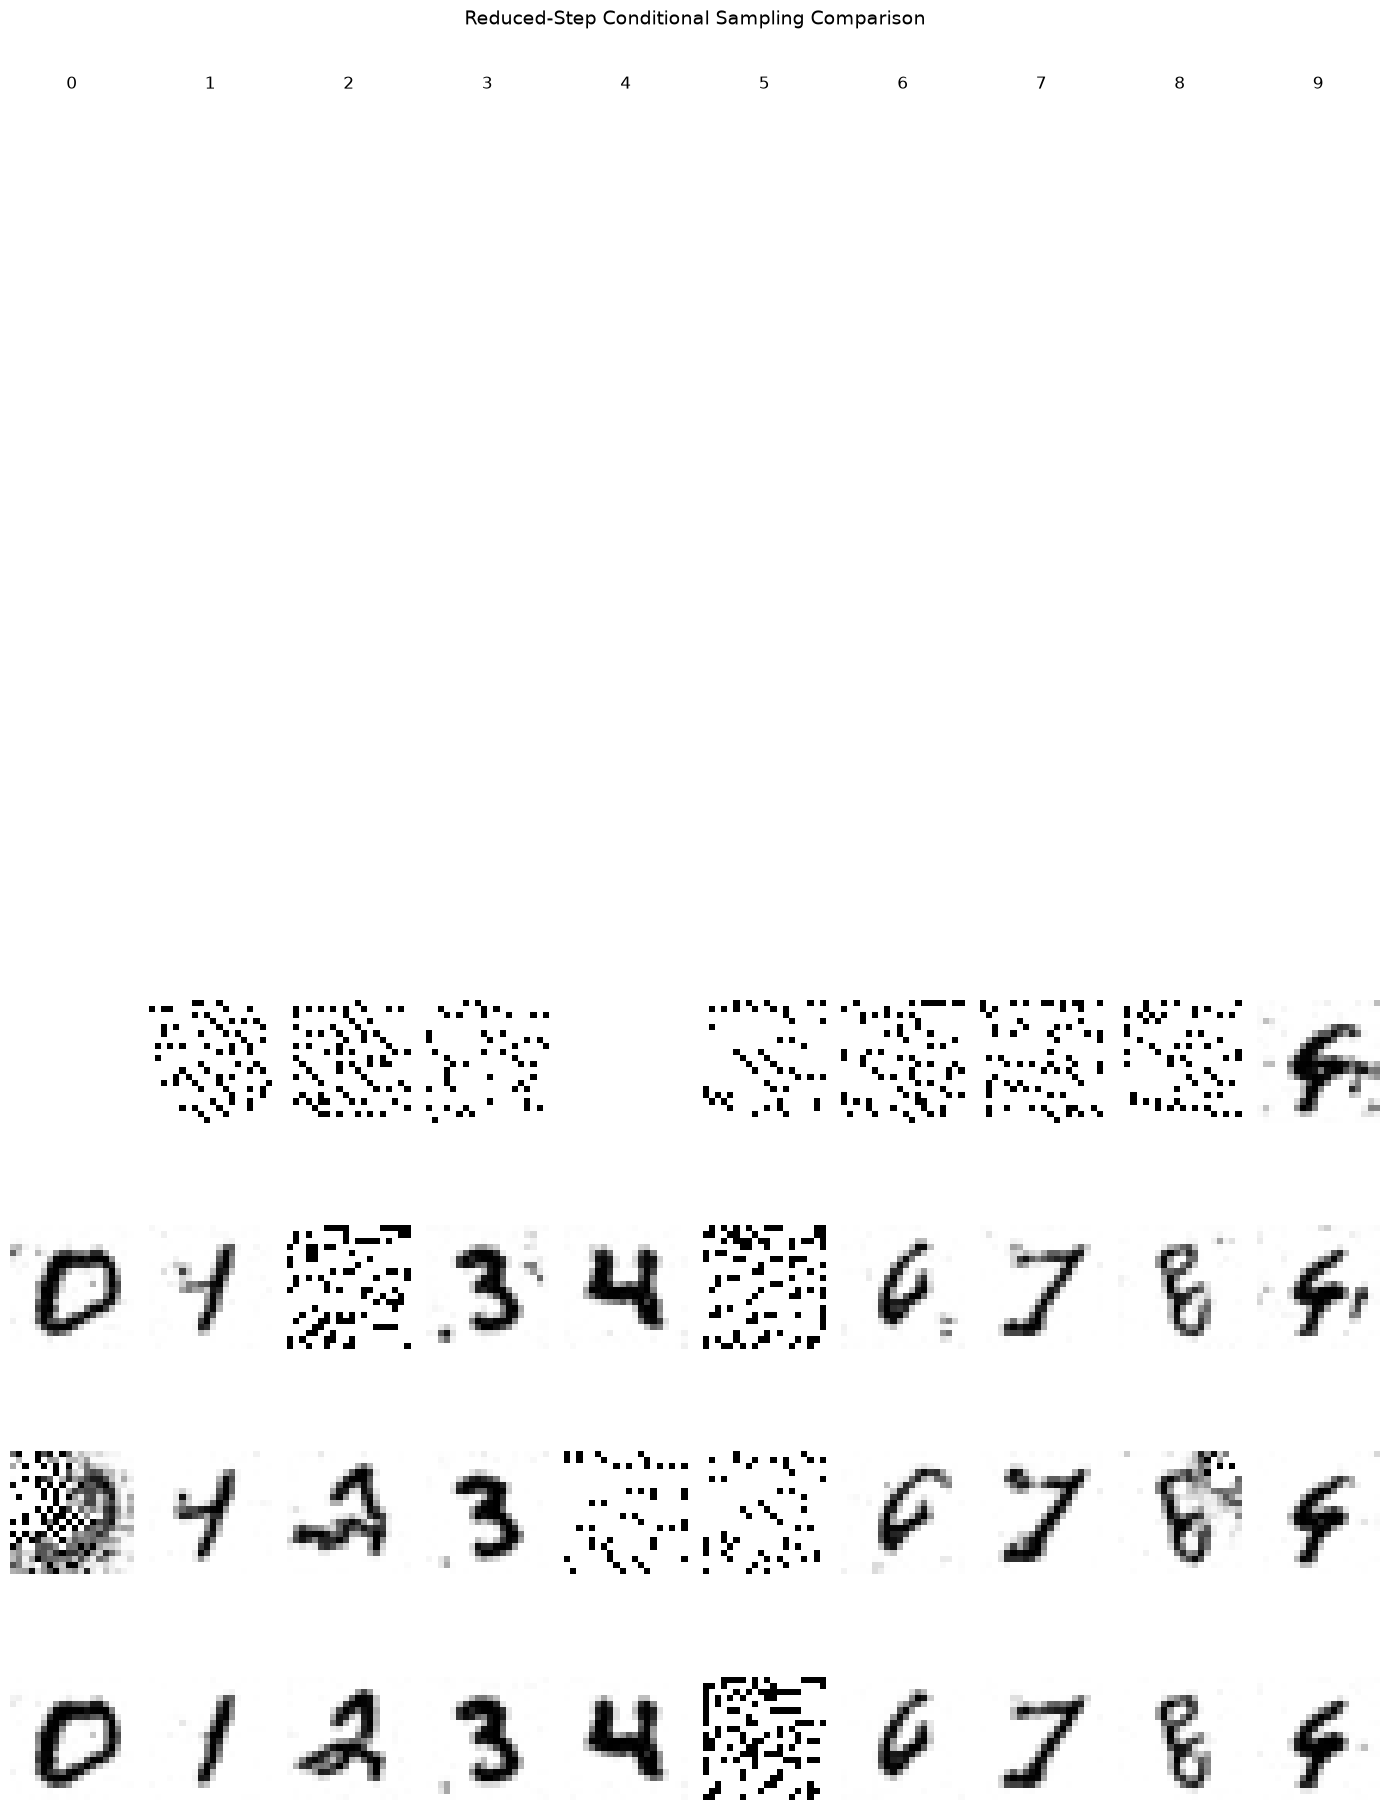

In [24]:
fig, axes = plt.subplots(
    len(REDUCED_STEP_COUNTS) * 2,
    NUM_CLASSES,
    figsize=(14, 2.4 * len(REDUCED_STEP_COUNTS) * 2)
)

row = 0

for sampling_steps in REDUCED_STEP_COUNTS:
    for schedule_name in ["linear", "cosine"]:
        samples = reduced_results[schedule_name][sampling_steps]["samples"]

        display_samples = (
            (samples.detach().cpu() + 1.0) / 2.0
        ).clamp(0, 1)

        for digit in range(NUM_CLASSES):
            sample_index = digit * SAMPLES_PER_CLASS

            axes[row, digit].imshow(
                display_samples[sample_index, 0],
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[row, digit].axis("off")

            if row == 0:
                axes[row, digit].set_title(str(digit))

        axes[row, 0].set_ylabel(
            f"{schedule_name.title()}\n{sampling_steps}",
            fontsize=10
        )

        row += 1

plt.suptitle(
    "Reduced-Step Conditional Sampling Comparison",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "reduced_step_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### 15.4 Runtime vs Step Count

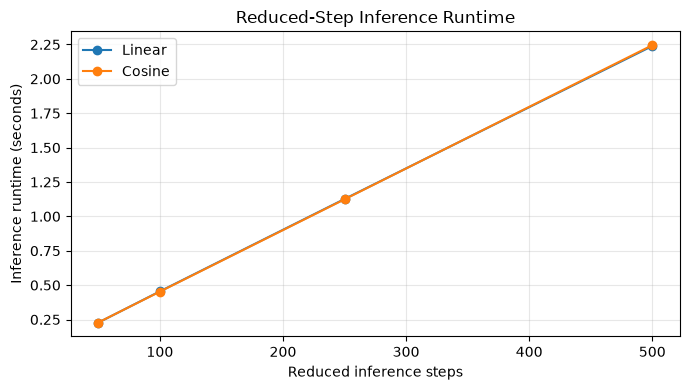

In [25]:
linear_reduced_times = [
    reduced_results["linear"][steps]["runtime"]
    for steps in REDUCED_STEP_COUNTS
]

cosine_reduced_times = [
    reduced_results["cosine"][steps]["runtime"]
    for steps in REDUCED_STEP_COUNTS
]

plt.figure(figsize=(7, 4))

plt.plot(
    REDUCED_STEP_COUNTS,
    linear_reduced_times,
    marker="o",
    label="Linear"
)

plt.plot(
    REDUCED_STEP_COUNTS,
    cosine_reduced_times,
    marker="o",
    label="Cosine"
)

plt.xlabel("Reduced inference steps")
plt.ylabel("Inference runtime (seconds)")
plt.title("Reduced-Step Inference Runtime")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "reduced_step_runtime.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 16. Final Experimental Summary

The table below combines the full-step DDPM results with the reduced-step
inference runtime comparison.

In [26]:
print("Final Experimental Summary")
print("=" * 80)

print("\nFull 1000-step DDPM results")
print("-" * 80)

print(
    f"{'Metric':30}"
    f"{'Linear':>18}"
    f"{'Cosine':>18}"
)

print("-" * 80)

print(
    f"{'Diffusion timesteps':30}"
    f"{LINEAR_TIMESTEPS:>18}"
    f"{COSINE_TIMESTEPS:>18}"
)

print(
    f"{'Final training MSE':30}"
    f"{linear_final_loss:>18.6f}"
    f"{cosine_final_loss:>18.6f}"
)

print(
    f"{'Training time (s)':30}"
    f"{linear_training_time:>18.2f}"
    f"{cosine_training_time:>18.2f}"
)

print(
    f"{'Full inference time (s)':30}"
    f"{linear_ddpm_time:>18.2f}"
    f"{cosine_ddpm_time:>18.2f}"
)

print(
    f"{'Generated samples':30}"
    f"{len(linear_samples):>18}"
    f"{len(cosine_samples):>18}"
)

print("\nReduced-step runtime results")
print("-" * 80)

print(
    f"{'Steps':12}"
    f"{'Linear (s)':>18}"
    f"{'Cosine (s)':>18}"
)

print("-" * 80)

for sampling_steps in REDUCED_STEP_COUNTS:
    linear_time = reduced_results["linear"][sampling_steps]["runtime"]
    cosine_time = reduced_results["cosine"][sampling_steps]["runtime"]

    print(
        f"{sampling_steps:<12}"
        f"{linear_time:>18.2f}"
        f"{cosine_time:>18.2f}"
    )

Final Experimental Summary

Full 1000-step DDPM results
--------------------------------------------------------------------------------
Metric                                    Linear            Cosine
--------------------------------------------------------------------------------
Diffusion timesteps                         1000              1000
Final training MSE                      0.028199          0.047993
Training time (s)                        1211.42           1210.30
Full inference time (s)                     4.74              4.56
Generated samples                            120               120

Reduced-step runtime results
--------------------------------------------------------------------------------
Steps               Linear (s)        Cosine (s)
--------------------------------------------------------------------------------
500                       2.24              2.24
250                       1.13              1.12
100                       0.45           